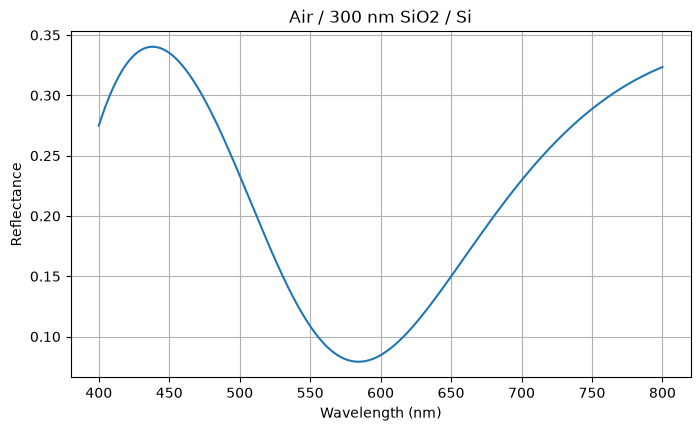

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tmm import coh_tmm

# 真空波长，单位 nm
wavelengths = np.linspace(400, 800, 401)

# 空气 / 300 nm SiO2 / 硅基底
# 这里为了演示，将折射率暂时近似为不随波长变化
n_list = [
    1.0,          # 空气
    1.46,         # SiO2
    3.8 + 0.02j,  # Si；实部为 n，虚部为 k
]

# 各层厚度，必须与波长使用相同单位
# 第一层和最后一层是半无限介质，因此写 np.inf
d_list = [
    np.inf,
    300,
    np.inf,
]

reflectance = []

for wavelength in wavelengths:
    result = coh_tmm(
        pol="s",           # s 偏振
        n_list=n_list,
        d_list=d_list,
        th_0=0,            # 正入射，单位为弧度
        lam_vac=wavelength
    )
    reflectance.append(result["R"])

plt.figure(figsize=(8, 4.5))
plt.plot(wavelengths, reflectance)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectance")
plt.title("Air / 300 nm SiO2 / Si")
plt.grid(True)
plt.show()